In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    cross_validate
)

from sklearn.preprocessing import (
    OneHotEncoder
)

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
data_path = (
    "/content/drive/MyDrive/"
    "AutoSenseAI/data/duration/"
    "service_duration_benchmark.csv"
)

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (314, 11)


,fix_id,code_id,fix_title,probability_rank,difficulty_level,est_parts_cost_min_usd,est_parts_cost_max_usd,parts_cost_mid_usd,parts_cost_range_usd,est_labor_hours,labor_minutes
0,849,213,Inspect wheel speed sensor connector and harne...,1,Easy DIY,5.0,25.0,15.0,20.0,0.4,24.0
1,850,213,Test wheel speed sensor resistance and signal,2,Moderate DIY,10.0,40.0,25.0,30.0,0.6,36.0
2,851,213,Replace wheel speed sensor,3,Moderate DIY,30.0,120.0,75.0,90.0,0.6,36.0
3,852,213,Repair chafed wheel speed sensor harness wiring,4,Professional Required,15.0,65.0,40.0,50.0,1.2,72.0
4,865,217,Inspect wheel speed sensor connector and harne...,1,Easy DIY,5.0,25.0,15.0,20.0,0.4,24.0


In [4]:
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget summary:")
print(df["est_labor_hours"].describe())

['fix_id', 'code_id', 'fix_title', 'probability_rank', 'difficulty_level', 'est_parts_cost_min_usd', 'est_parts_cost_max_usd', 'parts_cost_mid_usd', 'parts_cost_range_usd', 'est_labor_hours', 'labor_minutes']

Missing values:
fix_id                    0
code_id                   0
fix_title                 0
probability_rank          0
difficulty_level          0
est_parts_cost_min_usd    0
est_parts_cost_max_usd    0
parts_cost_mid_usd        0
parts_cost_range_usd      0
est_labor_hours           0
labor_minutes             0
dtype: int64

Target summary:
count    314.000000
mean       1.069745
std        0.761373
min        0.200000
25%        0.600000
50%        1.000000
75%        1.300000
max        4.500000
Name: est_labor_hours, dtype: float64


In [5]:
target = "est_labor_hours"

y = df[target].copy()

In [6]:
groups = df["fix_title"].copy()

print("Rows:", len(df))
print("Unique repair titles:", groups.nunique())

Rows: 314
Unique repair titles: 174


In [7]:
task_only_features = [
    "fix_title",
    "difficulty_level",
    "probability_rank"
]

In [8]:
task_cost_features = [
    "fix_title",
    "difficulty_level",
    "probability_rank",
    "parts_cost_mid_usd",
    "parts_cost_range_usd"
]

In [9]:
print("Task-only features:")
print(task_only_features)

print("\nTask + cost features:")
print(task_cost_features)

Task-only features:
['fix_title', 'difficulty_level', 'probability_rank']

Task + cost features:
['fix_title', 'difficulty_level', 'probability_rank', 'parts_cost_mid_usd', 'parts_cost_range_usd']


In [10]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df,
        y,
        groups=groups
    )
)

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

print("Train rows:", len(train_df))
print("Test rows:", len(test_df))

print(
    "Train unique titles:",
    train_df["fix_title"].nunique()
)

print(
    "Test unique titles:",
    test_df["fix_title"].nunique()
)

Train rows: 255
Test rows: 59
Train unique titles: 139
Test unique titles: 35


In [11]:
train_titles = set(
    train_df["fix_title"]
)

test_titles = set(
    test_df["fix_title"]
)

title_overlap = train_titles.intersection(
    test_titles
)

print(
    "Repair titles appearing in both train and test:",
    len(title_overlap)
)

print(title_overlap)

Repair titles appearing in both train and test: 0
set()


In [12]:
y_train = train_df[target].copy()
y_test = test_df[target].copy()

print("Training target mean:", round(y_train.mean(), 3))
print("Testing target mean:", round(y_test.mean(), 3))

Training target mean: 1.085
Testing target mean: 1.003


In [13]:
def regression_metrics(
    model_name,
    y_true,
    y_pred
):
    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "Model": model_name,
        "MAE_Hours": mae,
        "MAE_Minutes": mae * 60,
        "RMSE_Hours": rmse,
        "RMSE_Minutes": rmse * 60,
        "R2": r2
    }

In [14]:
global_mean = y_train.mean()

global_mean_predictions = np.full(
    len(y_test),
    global_mean
)

global_mean_metrics = regression_metrics(
    "Global Mean Baseline",
    y_test,
    global_mean_predictions
)

global_mean_metrics

{'Model': 'Global Mean Baseline',
 'MAE_Hours': 0.4268993020937188,
 'MAE_Minutes': 25.613958125623128,
 'RMSE_Hours': np.float64(0.5646840977482662),
 'RMSE_Minutes': np.float64(33.881045864895974),
 'R2': -0.02138502438436185}

In [15]:
difficulty_means = (
    train_df
    .groupby("difficulty_level")[target]
    .mean()
    .to_dict()
)

difficulty_means

{'Easy DIY': 0.5,
 'Moderate DIY': 0.9868686868686869,
 'Professional Required': 1.8466666666666667}

In [16]:
difficulty_predictions = (
    test_df["difficulty_level"]
    .map(difficulty_means)
    .fillna(global_mean)
    .values
)

In [17]:
difficulty_mean_metrics = regression_metrics(
    "Difficulty Mean Baseline",
    y_test,
    difficulty_predictions
)

difficulty_mean_metrics

{'Model': 'Difficulty Mean Baseline',
 'MAE_Hours': 0.31184043828111624,
 'MAE_Minutes': 18.710426296866974,
 'RMSE_Hours': np.float64(0.4539659643811179),
 'RMSE_Minutes': np.float64(27.237957862867074),
 'R2': 0.33987685921364696}

In [18]:
task_only_preprocessor = ColumnTransformer(
    transformers=[
        (
            "title_text",
            TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2),
                min_df=1,
                max_features=1000
            ),
            "fix_title"
        ),

        (
            "difficulty",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            ["difficulty_level"]
        ),

        (
            "numeric",
            SimpleImputer(
                strategy="median"
            ),
            ["probability_rank"]
        )
    ]
)

In [19]:
task_cost_preprocessor = ColumnTransformer(
    transformers=[
        (
            "title_text",
            TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2),
                min_df=1,
                max_features=1000
            ),
            "fix_title"
        ),

        (
            "difficulty",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            ["difficulty_level"]
        ),

        (
            "numeric",
            SimpleImputer(
                strategy="median"
            ),
            [
                "probability_rank",
                "parts_cost_mid_usd",
                "parts_cost_range_usd"
            ]
        )
    ]
)

In [20]:
rf_task_pipeline = Pipeline([
    (
        "preprocessor",
        task_only_preprocessor
    ),

    (
        "regressor",
        RandomForestRegressor(
            n_estimators=500,
            max_depth=12,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [21]:
rf_task_pipeline.fit(
    train_df[task_only_features],
    y_train
)

print(
    "Task-only Random Forest training complete."
)

Task-only Random Forest training complete.


In [22]:
rf_task_pred = rf_task_pipeline.predict(
    test_df[task_only_features]
)

rf_task_metrics = regression_metrics(
    "Random Forest - Task Only",
    y_test,
    rf_task_pred
)

rf_task_metrics

{'Model': 'Random Forest - Task Only',
 'MAE_Hours': 0.25320858538814717,
 'MAE_Minutes': 15.19251512328883,
 'RMSE_Hours': np.float64(0.3973241045127545),
 'RMSE_Minutes': np.float64(23.839446270765272),
 'R2': 0.4943288259772277}

In [23]:
rf_cost_pipeline = Pipeline([
    (
        "preprocessor",
        task_cost_preprocessor
    ),

    (
        "regressor",
        RandomForestRegressor(
            n_estimators=500,
            max_depth=12,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [24]:
rf_cost_pipeline.fit(
    train_df[task_cost_features],
    y_train
)

print(
    "Task + cost Random Forest training complete."
)

Task + cost Random Forest training complete.


In [25]:
rf_cost_pred = rf_cost_pipeline.predict(
    test_df[task_cost_features]
)

rf_cost_metrics = regression_metrics(
    "Random Forest - Task + Cost",
    y_test,
    rf_cost_pred
)

rf_cost_metrics

{'Model': 'Random Forest - Task + Cost',
 'MAE_Hours': 0.19807000760538243,
 'MAE_Minutes': 11.884200456322946,
 'RMSE_Hours': np.float64(0.3135955210826164),
 'RMSE_Minutes': np.float64(18.815731264956984),
 'R2': 0.6849945459955892}

In [26]:
xgb_task_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=2,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [27]:
xgb_task_pipeline = Pipeline([
    (
        "preprocessor",
        task_only_preprocessor
    ),
    (
        "regressor",
        xgb_task_model
    )
])

In [28]:
xgb_task_pipeline.fit(
    train_df[task_only_features],
    y_train
)

print(
    "Task-only XGBoost training complete."
)

Task-only XGBoost training complete.


In [29]:
xgb_task_pred = xgb_task_pipeline.predict(
    test_df[task_only_features]
)

xgb_task_metrics = regression_metrics(
    "XGBoost - Task Only",
    y_test,
    xgb_task_pred
)

xgb_task_metrics

{'Model': 'XGBoost - Task Only',
 'MAE_Hours': 0.25057613051543803,
 'MAE_Minutes': 15.034567830926282,
 'RMSE_Hours': np.float64(0.41202490757182764),
 'RMSE_Minutes': np.float64(24.721494454309656),
 'R2': 0.45621739363253955}

In [30]:
xgb_cost_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=2,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [31]:
xgb_cost_pipeline = Pipeline([
    (
        "preprocessor",
        task_cost_preprocessor
    ),
    (
        "regressor",
        xgb_cost_model
    )
])

In [32]:
xgb_cost_pipeline.fit(
    train_df[task_cost_features],
    y_train
)

print(
    "Task + cost XGBoost training complete."
)

Task + cost XGBoost training complete.


In [33]:
xgb_cost_pred = xgb_cost_pipeline.predict(
    test_df[task_cost_features]
)

xgb_cost_metrics = regression_metrics(
    "XGBoost - Task + Cost",
    y_test,
    xgb_cost_pred
)

xgb_cost_metrics

{'Model': 'XGBoost - Task + Cost',
 'MAE_Hours': 0.19143866644067278,
 'MAE_Minutes': 11.486319986440368,
 'RMSE_Hours': np.float64(0.28569840951032477),
 'RMSE_Minutes': np.float64(17.141904570619488),
 'R2': 0.7385467672618893}

In [34]:
comparison_df = pd.DataFrame([
    global_mean_metrics,
    difficulty_mean_metrics,
    rf_task_metrics,
    rf_cost_metrics,
    xgb_task_metrics,
    xgb_cost_metrics
])

comparison_df

,Model,MAE_Hours,MAE_Minutes,RMSE_Hours,RMSE_Minutes,R2
0,Global Mean Baseline,0.426899,25.613958,0.564684,33.881046,-0.021385
1,Difficulty Mean Baseline,0.311840,18.710426,0.453966,27.237958,0.339877
2,Random Forest - Task Only,0.253209,15.192515,0.397324,23.839446,0.494329
3,Random Forest - Task + Cost,0.198070,11.884200,0.313596,18.815731,0.684995
4,XGBoost - Task Only,0.250576,15.034568,0.412025,24.721494,0.456217
5,XGBoost - Task + Cost,0.191439,11.486320,0.285698,17.141905,0.738547


In [35]:
comparison_sorted = comparison_df.sort_values(
    by="MAE_Hours",
    ascending=True
)

comparison_sorted

,Model,MAE_Hours,MAE_Minutes,RMSE_Hours,RMSE_Minutes,R2
5,XGBoost - Task + Cost,0.191439,11.486320,0.285698,17.141905,0.738547
3,Random Forest - Task + Cost,0.198070,11.884200,0.313596,18.815731,0.684995
4,XGBoost - Task Only,0.250576,15.034568,0.412025,24.721494,0.456217
2,Random Forest - Task Only,0.253209,15.192515,0.397324,23.839446,0.494329
1,Difficulty Mean Baseline,0.311840,18.710426,0.453966,27.237958,0.339877
0,Global Mean Baseline,0.426899,25.613958,0.564684,33.881046,-0.021385


In [36]:
ml_results = comparison_df[
    comparison_df["Model"].str.contains(
        "Random Forest|XGBoost",
        regex=True
    )
].copy()

best_ml_row = ml_results.loc[
    ml_results["MAE_Hours"].idxmin()
]

print("Best ML model:")
print(best_ml_row)

Best ML model:
Model           XGBoost - Task + Cost
MAE_Hours                    0.191439
MAE_Minutes                  11.48632
RMSE_Hours                   0.285698
RMSE_Minutes                17.141905
R2                           0.738547
Name: 5, dtype: object


In [37]:
best_ml_mae = best_ml_row["MAE_Hours"]

baseline_mae = min(
    global_mean_metrics["MAE_Hours"],
    difficulty_mean_metrics["MAE_Hours"]
)

improvement_percent = (
    (baseline_mae - best_ml_mae)
    / baseline_mae
    * 100
)

print(
    "Best baseline MAE:",
    round(baseline_mae, 3),
    "hours"
)

print(
    "Best ML MAE:",
    round(best_ml_mae, 3),
    "hours"
)

print(
    "MAE improvement over best baseline:",
    round(improvement_percent, 2),
    "%"
)

Best baseline MAE: 0.312 hours
Best ML MAE: 0.191 hours
MAE improvement over best baseline: 38.61 %


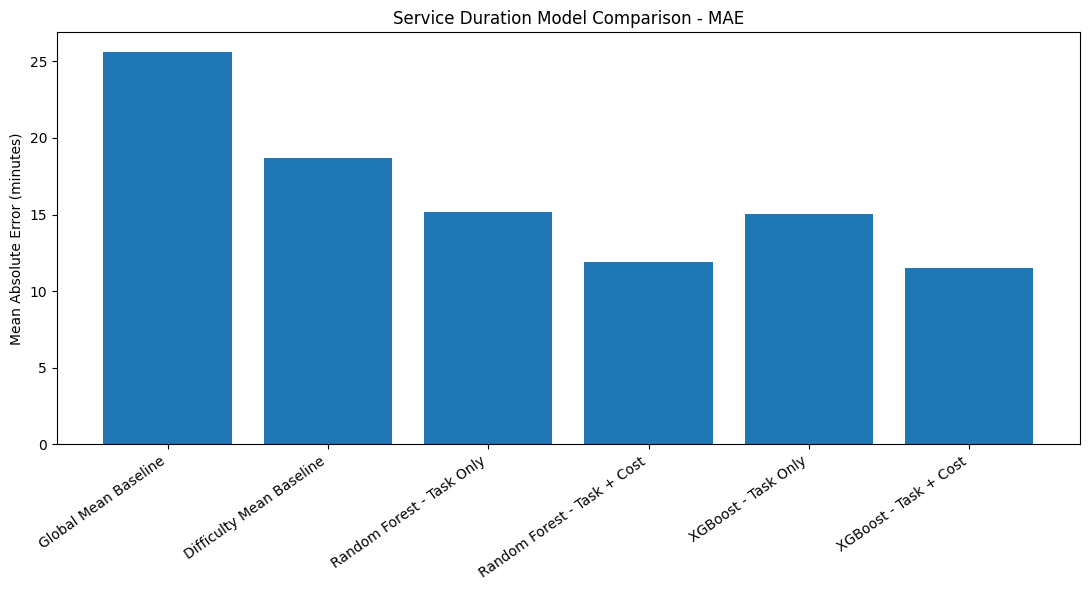

In [38]:
plt.figure(figsize=(11, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["MAE_Minutes"]
)

plt.title(
    "Service Duration Model Comparison - MAE"
)

plt.ylabel(
    "Mean Absolute Error (minutes)"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

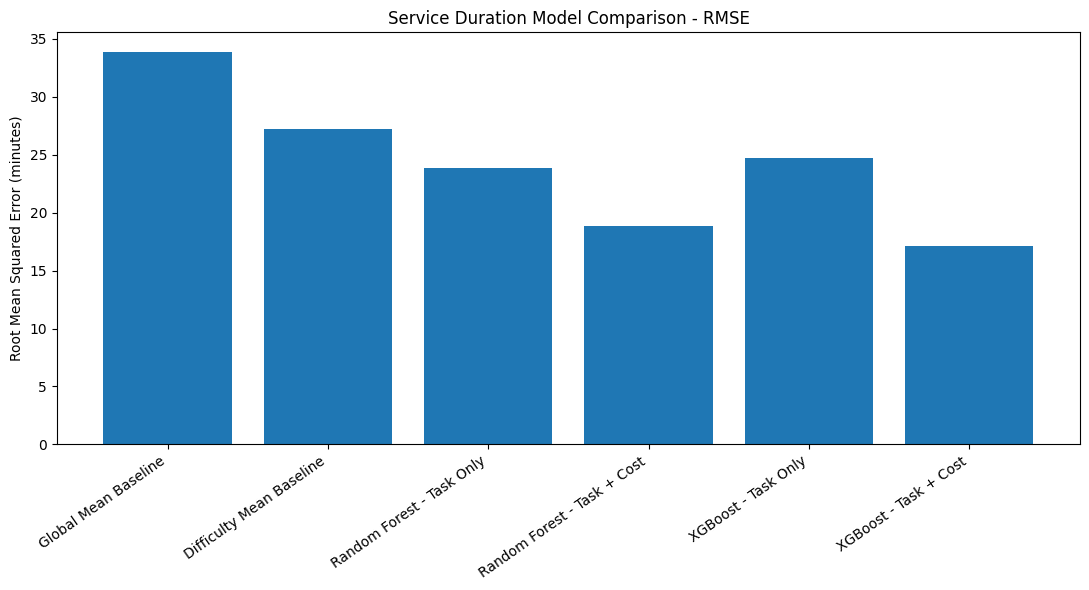

In [39]:
plt.figure(figsize=(11, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["RMSE_Minutes"]
)

plt.title(
    "Service Duration Model Comparison - RMSE"
)

plt.ylabel(
    "Root Mean Squared Error (minutes)"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

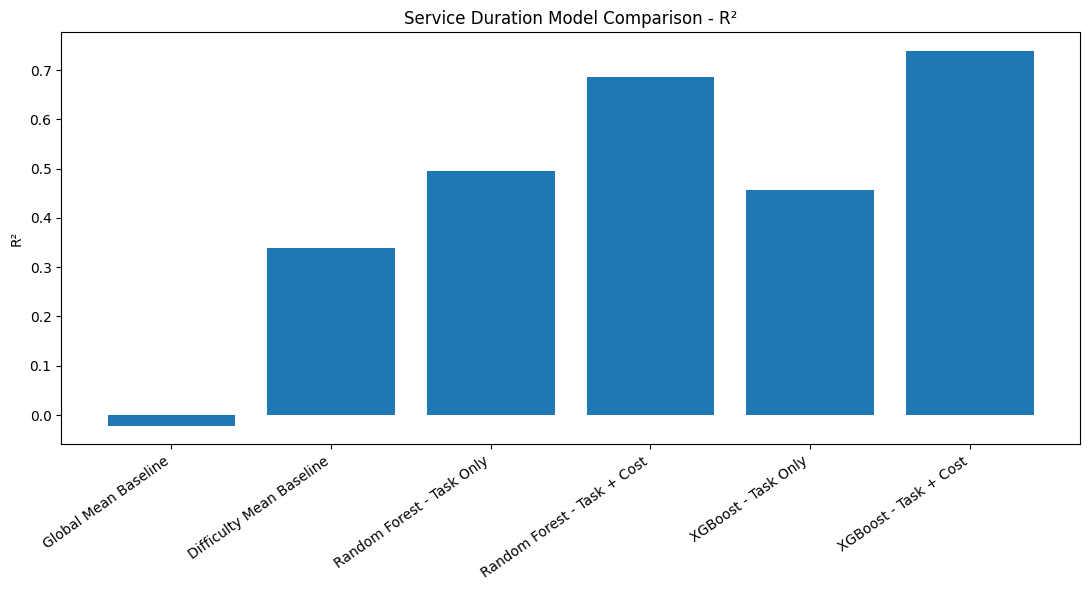

In [40]:
plt.figure(figsize=(11, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["R2"]
)

plt.title(
    "Service Duration Model Comparison - R²"
)

plt.ylabel("R²")

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

In [41]:
prediction_map = {
    "Random Forest - Task Only": rf_task_pred,
    "Random Forest - Task + Cost": rf_cost_pred,
    "XGBoost - Task Only": xgb_task_pred,
    "XGBoost - Task + Cost": xgb_cost_pred
}

best_model_name = best_ml_row["Model"]

best_predictions = prediction_map[
    best_model_name
]

print(
    "Best model for visualization:",
    best_model_name
)

Best model for visualization: XGBoost - Task + Cost


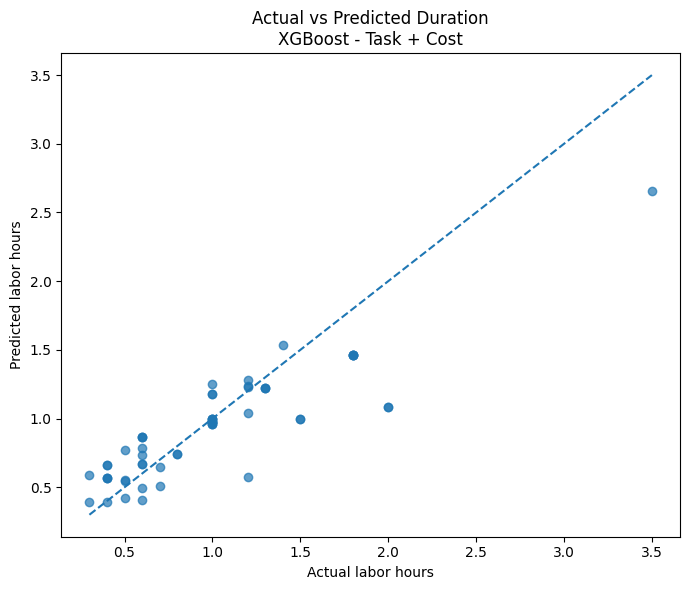

In [42]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.7
)

minimum = min(
    y_test.min(),
    best_predictions.min()
)

maximum = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual labor hours")
plt.ylabel("Predicted labor hours")

plt.title(
    f"Actual vs Predicted Duration\n{best_model_name}"
)

plt.tight_layout()
plt.show()

In [43]:
prediction_examples = test_df[
    [
        "fix_title",
        "difficulty_level",
        "est_labor_hours"
    ]
].copy()

prediction_examples[
    "predicted_labor_hours"
] = best_predictions

prediction_examples[
    "actual_minutes"
] = (
    prediction_examples[
        "est_labor_hours"
    ] * 60
)

prediction_examples[
    "predicted_minutes"
] = (
    prediction_examples[
        "predicted_labor_hours"
    ] * 60
)

prediction_examples[
    "absolute_error_minutes"
] = abs(
    prediction_examples[
        "actual_minutes"
    ]
    -
    prediction_examples[
        "predicted_minutes"
    ]
)

prediction_examples.head(15)

,fix_title,difficulty_level,est_labor_hours,predicted_labor_hours,actual_minutes,predicted_minutes,absolute_error_minutes
9,Inspect brake pedal switch connector,Easy DIY,0.3,0.391972,18.0,23.518309,5.518309
10,Replace brake pedal switch,Moderate DIY,0.5,0.769295,30.0,46.157707,16.157707
23,Repair MAP sensor circuit wiring,Professional Required,1.2,1.226893,72.0,73.613586,1.613586
35,Repair throttle/pedal position sensor wiring,Professional Required,1.3,1.226027,78.0,73.561607,4.438393
42,"Inspect for contamination sources (oil, coolan...",Easy DIY,0.8,0.742744,48.0,44.564625,3.435375
43,Replace slow-responding oxygen sensor,Moderate DIY,0.6,0.668742,36.0,40.124508,4.124508
45,Test O2 sensor heater circuit fuse and relay,Easy DIY,0.4,0.563908,24.0,33.834480,9.834480
51,Test O2 sensor heater circuit fuse and relay,Easy DIY,0.4,0.563908,24.0,33.834480,9.834480
55,Replace fuel filter and test fuel pump output,Moderate DIY,1.0,0.971996,60.0,58.319786,1.680214
59,Replace stuck-open fuel pressure regulator,Moderate DIY,1.0,0.993548,60.0,59.612877,0.387123


In [44]:
X_full = df[task_cost_features]
y_full = df[target]
groups_full = df["fix_title"]

In [45]:
group_cv = GroupKFold(
    n_splits=5
)

In [46]:
scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "r2": "r2"
}

In [47]:
rf_cv_results = cross_validate(
    rf_cost_pipeline,
    X_full,
    y_full,
    groups=groups_full,
    cv=group_cv,
    scoring=scoring,
    n_jobs=1
)

In [48]:
rf_cv_mae = -rf_cv_results["test_mae"]

rf_cv_rmse = np.sqrt(
    -rf_cv_results["test_mse"]
)

rf_cv_r2 = rf_cv_results["test_r2"]

print(
    "Random Forest CV MAE:",
    np.round(rf_cv_mae, 3)
)

print(
    "Mean MAE:",
    round(rf_cv_mae.mean(), 3),
    "hours"
)

print(
    "Mean MAE:",
    round(rf_cv_mae.mean() * 60, 2),
    "minutes"
)

print(
    "Mean RMSE:",
    round(rf_cv_rmse.mean(), 3),
    "hours"
)

print(
    "Mean R²:",
    round(rf_cv_r2.mean(), 3)
)

Random Forest CV MAE: [0.209 0.172 0.207 0.362 0.215]
Mean MAE: 0.233 hours
Mean MAE: 13.98 minutes
Mean RMSE: 0.395 hours
Mean R²: 0.642


In [49]:
xgb_cv_results = cross_validate(
    xgb_cost_pipeline,
    X_full,
    y_full,
    groups=groups_full,
    cv=group_cv,
    scoring=scoring,
    n_jobs=1
)

In [50]:
xgb_cv_mae = -xgb_cv_results["test_mae"]

xgb_cv_rmse = np.sqrt(
    -xgb_cv_results["test_mse"]
)

xgb_cv_r2 = xgb_cv_results["test_r2"]

print(
    "XGBoost CV MAE:",
    np.round(xgb_cv_mae, 3)
)

print(
    "Mean MAE:",
    round(xgb_cv_mae.mean(), 3),
    "hours"
)

print(
    "Mean MAE:",
    round(xgb_cv_mae.mean() * 60, 2),
    "minutes"
)

print(
    "Mean RMSE:",
    round(xgb_cv_rmse.mean(), 3),
    "hours"
)

print(
    "Mean R²:",
    round(xgb_cv_r2.mean(), 3)
)

XGBoost CV MAE: [0.256 0.262 0.207 0.334 0.217]
Mean MAE: 0.255 hours
Mean MAE: 15.32 minutes
Mean RMSE: 0.411 hours
Mean R²: 0.605


In [51]:
cv_comparison = pd.DataFrame({
    "Model": [
        "Random Forest - Task + Cost",
        "XGBoost - Task + Cost"
    ],

    "CV_MAE_Hours": [
        rf_cv_mae.mean(),
        xgb_cv_mae.mean()
    ],

    "CV_MAE_Minutes": [
        rf_cv_mae.mean() * 60,
        xgb_cv_mae.mean() * 60
    ],

    "CV_RMSE_Hours": [
        rf_cv_rmse.mean(),
        xgb_cv_rmse.mean()
    ],

    "CV_R2": [
        rf_cv_r2.mean(),
        xgb_cv_r2.mean()
    ]
})

cv_comparison

,Model,CV_MAE_Hours,CV_MAE_Minutes,CV_RMSE_Hours,CV_R2
0,Random Forest - Task + Cost,0.232939,13.976314,0.394941,0.642104
1,XGBoost - Task + Cost,0.255329,15.319751,0.411135,0.604864


In [52]:
results_dir = (
    "/content/drive/MyDrive/"
    "AutoSenseAI/results"
)

os.makedirs(
    results_dir,
    exist_ok=True
)

In [53]:
comparison_df.to_csv(
    os.path.join(
        results_dir,
        "service_duration_model_comparison.csv"
    ),
    index=False
)

cv_comparison.to_csv(
    os.path.join(
        results_dir,
        "service_duration_group_cv_comparison.csv"
    ),
    index=False
)

prediction_examples.to_csv(
    os.path.join(
        results_dir,
        "service_duration_prediction_examples.csv"
    ),
    index=False
)

print("Results saved successfully.")

Results saved successfully.


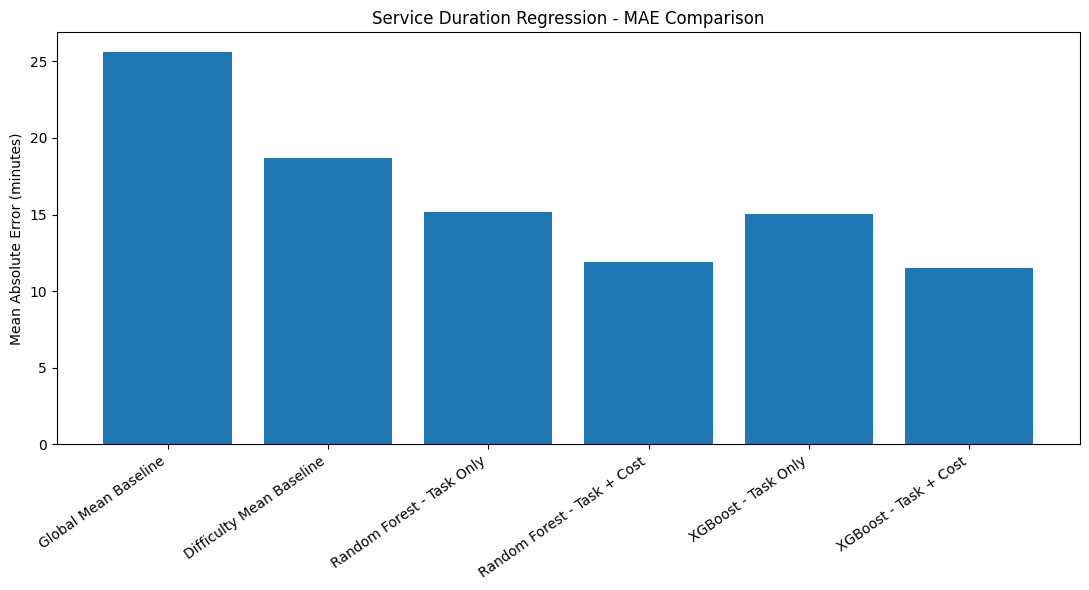

Saved: /content/drive/MyDrive/AutoSenseAI/results/service_duration_mae_comparison.png


In [54]:
plt.figure(figsize=(11, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["MAE_Minutes"]
)

plt.title(
    "Service Duration Regression - MAE Comparison"
)

plt.ylabel(
    "Mean Absolute Error (minutes)"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

mae_chart_path = os.path.join(
    results_dir,
    "service_duration_mae_comparison.png"
)

plt.savefig(
    mae_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", mae_chart_path)

In [55]:
model_dir = (
    "/content/drive/MyDrive/"
    "AutoSenseAI/models"
)

os.makedirs(
    model_dir,
    exist_ok=True
)

In [56]:
joblib.dump(
    rf_cost_pipeline,
    os.path.join(
        model_dir,
        "service_duration_random_forest_candidate.pkl"
    )
)

joblib.dump(
    xgb_cost_pipeline,
    os.path.join(
        model_dir,
        "service_duration_xgboost_candidate.pkl"
    )
)

print("Candidate models saved.")

Candidate models saved.


In [57]:
sample = test_df[
    task_cost_features
].iloc[[0]]

sample

,fix_title,difficulty_level,probability_rank,parts_cost_mid_usd,parts_cost_range_usd
9,Inspect brake pedal switch connector,Easy DIY,2,12.5,15.0


In [58]:
sample_prediction = (
    xgb_cost_pipeline.predict(
        sample
    )[0]
)

print(
    "Predicted labor hours:",
    round(sample_prediction, 2)
)

print(
    "Predicted labor minutes:",
    round(sample_prediction * 60)
)

print(
    "Actual labor hours:",
    test_df.iloc[0][
        "est_labor_hours"
    ]
)

Predicted labor hours: 0.39
Predicted labor minutes: 24
Actual labor hours: 0.3


## Service Duration Regression Experiment

Objective:
Estimate the labor duration of a predicted maintenance/repair task.

Dataset:
MechanicDB diagnostic repair sample.

Target:
Estimated labor hours.

Important Dataset Limitation:
The target contains estimated labor times rather than observed real-world
workshop completion times. Therefore this dataset is used as an initial
regression benchmark and proof of concept.

Data Leakage Control:
Repeated repair titles had identical duration values. Therefore a normal
random row split could allow the model to memorize repair titles.

To reduce this risk, GroupShuffleSplit was used with fix_title as the group,
ensuring that the same repair title does not appear in both training and
testing data.

Features:
- Repair task title
- Difficulty level
- Probability rank
- Estimated parts cost information

Text Processing:
TF-IDF was used for repair titles so the regression models can generalize
from words and phrases in previously unseen repair tasks.

Compared Methods:
1. Global Mean Baseline
2. Difficulty Mean Baseline
3. Random Forest Regressor — Task Only
4. Random Forest Regressor — Task + Cost
5. XGBoost Regressor — Task Only
6. XGBoost Regressor — Task + Cost

Evaluation:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R²

Additional Validation:
5-fold GroupKFold cross-validation was used to assess generalization across
unseen repair titles.

Final Result:
[Insert actual results after evaluation.]

Selected Model:
[Do not fill until comparison and cross-validation are reviewed.]

Research Limitation:
This benchmark estimates typical repair labor time. It should not be
interpreted as guaranteed real-world workshop elapsed completion time.
Future validation should use historical service-center records containing
actual start/end times or labor hours.